In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("../data/milk_prices.csv", parse_dates=["date"]).sort_values("date").reset_index(drop=True)
df.head()

,date,price
0,2022-01-01,0.553
1,2022-01-02,0.540
2,2022-01-03,0.559
3,2022-01-04,0.562
4,2022-01-05,0.533


In [9]:
def make_features(d):
    d = d.copy()
    d["day_num"] = (d["date"] - d["date"].min()).dt.days

    # calendar features
    d["month"] = d["date"].dt.month
    d["dayofweek"] = d["date"].dt.dayofweek
    d["dayofyear"] = d["date"].dt.dayofyear

    # smooth yearly seasonality
    d["sin_year"] = np.sin(2 * np.pi * d["dayofyear"] / 365.25)
    d["cos_year"] = np.cos(2 * np.pi * d["dayofyear"] / 365.25)

    # lag features (past prices only)
    for k in (1, 7, 30):
        d[f"lag_{k}"] = d["price"].shift(k)

    # rolling means of the PREVIOUS days (shift(1) avoids leakage)
    for w in (7, 30):
        d[f"roll_mean_{w}"] = d["price"].shift(1).rolling(w).mean()
    return d

feat = make_features(df)
before = len(feat)
feat = feat.dropna().reset_index(drop=True)   # first 30 rows have no 30-day history
print(f"Rows: {before} -> {len(feat)} after dropping rows without history")
feat.head()

Rows: 1765 -> 1735 after dropping rows without history


C:\Users\Naveed\AppData\Local\Temp\ipykernel_23180\3939863929.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["dayofweek"] = d["date"].dt.dayofweek
C:\Users\Naveed\AppData\Local\Temp\ipykernel_23180\3939863929.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  d["dayofyear"] = d["date"].dt.dayofyear


,date,price,day_num,month,dayofweek,dayofyear,sin_year,cos_year,lag_1,lag_7,lag_30,roll_mean_7,roll_mean_30
0,2022-01-31,0.593,30,1,0,31,0.508356,0.861147,0.575,0.565,0.553,0.569857,0.560800
1,2022-02-01,0.568,31,2,1,32,0.523094,0.852275,0.593,0.563,0.540,0.573857,0.562133
2,2022-02-02,0.568,32,2,2,33,0.537677,0.843151,0.568,0.565,0.559,0.574571,0.563067
3,2022-02-03,0.565,33,2,3,34,0.552101,0.833777,0.568,0.574,0.562,0.575000,0.563367
4,2022-02-04,0.580,34,2,4,35,0.566362,0.824157,0.565,0.573,0.533,0.573714,0.563467


In [10]:
split = int(len(feat) * 0.8)
train, test = feat.iloc[:split], feat.iloc[split:]
print("Train:", train.shape, "| Test:", test.shape)
print("Train ends:", train["date"].max().date(), "| Test starts:", test["date"].min().date())

Train: (1388, 13) | Test: (347, 13)
Train ends: 2025-11-18 | Test starts: 2025-11-19


In [11]:
feature_sets = {
    "1. Baseline (day_num)": ["day_num"],
    "2. + Calendar": ["day_num", "month", "dayofweek", "dayofyear"],
    "3. + Seasonality (sin/cos)": ["day_num", "sin_year", "cos_year"],
    "4. + Lags": ["day_num", "sin_year", "cos_year", "lag_1", "lag_7", "lag_30"],
    "5. All features": ["day_num", "month", "dayofweek", "dayofyear", "sin_year", "cos_year",
                        "lag_1", "lag_7", "lag_30", "roll_mean_7", "roll_mean_30"],
}

rows, preds = [], {}
for name, cols in feature_sets.items():
    m = LinearRegression().fit(train[cols], train["price"])
    p = m.predict(test[cols])
    preds[name] = p
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(test["price"], p),
        "RMSE": np.sqrt(mean_squared_error(test["price"], p)),
        "R2": r2_score(test["price"], p),
    })

results = pd.DataFrame(rows).set_index("model").round(4)
results

,MAE,RMSE,R2
model,,,
1. Baseline (day_num),0.0267,0.0309,-0.3161
2. + Calendar,0.0180,0.0214,0.3693
3. + Seasonality (sin/cos),0.0081,0.0102,0.8570
4. + Lags,0.0081,0.0102,0.8568
5. All features,0.0082,0.0103,0.8541


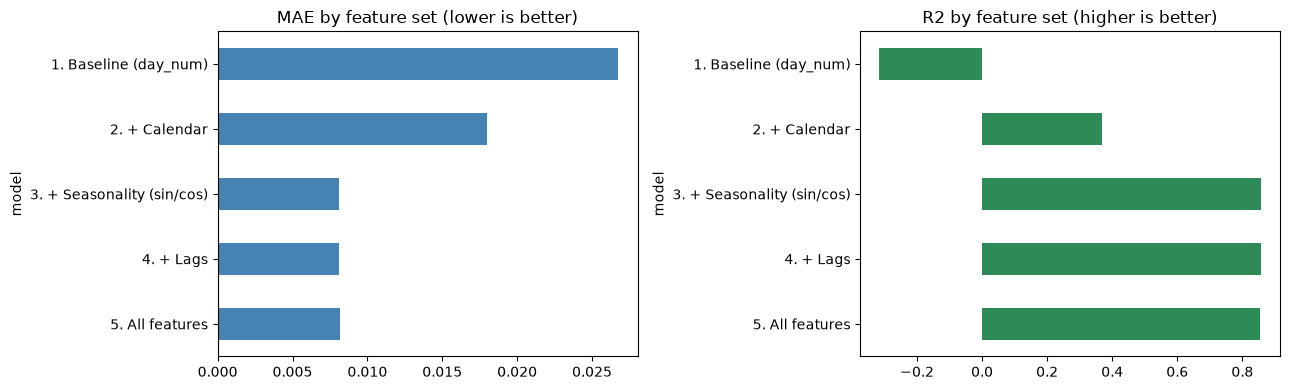

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
results["MAE"].plot.barh(ax=ax[0], color="steelblue")
ax[0].set_title("MAE by feature set (lower is better)")
ax[0].invert_yaxis()
results["R2"].plot.barh(ax=ax[1], color="seagreen")
ax[1].set_title("R2 by feature set (higher is better)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

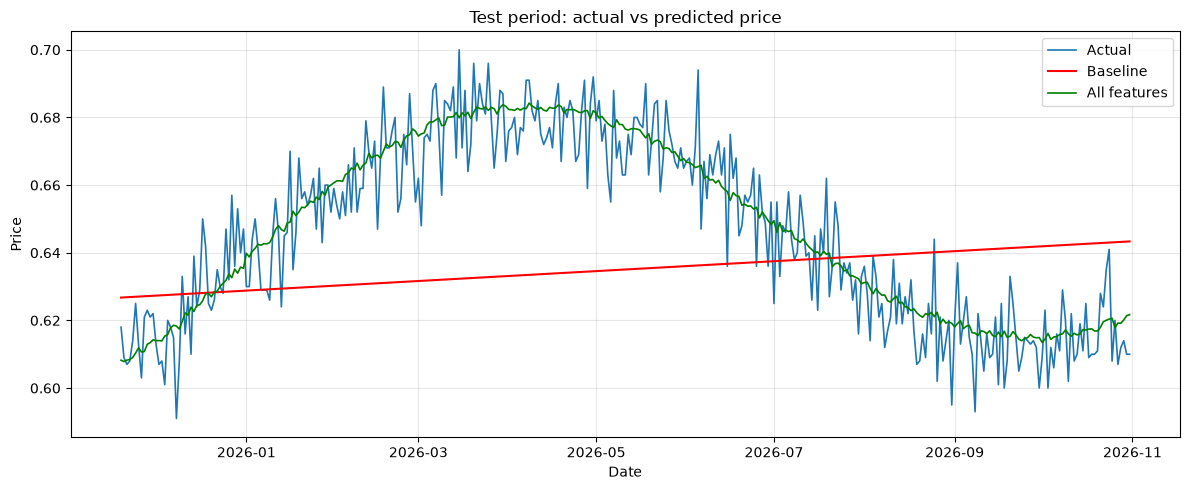

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(test["date"], test["price"], label="Actual", linewidth=1.2)
plt.plot(test["date"], preds["1. Baseline (day_num)"], label="Baseline", color="red", linewidth=1.5)
plt.plot(test["date"], preds["5. All features"], label="All features", color="green", linewidth=1.2)
plt.title("Test period: actual vs predicted price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
feat.to_csv("../data/milk_features.csv", index=False)
print("Saved", feat.shape, "to data/milk_features.csv")

Saved (1735, 13) to data/milk_features.csv
